# Predictive modeling of customer bookings

Machine learning model to predict whether airline customers complete a booking. Covers data cleaning, feature engineering, Random Forest, ROC AUC evaluation, and feature importance insights (Python, scikit-learn).

In [1]:
import pandas as pd

In [2]:
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
df = pd.read_csv("customer_booking.csv", encoding="latin1")
df.head()

,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,Sat,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,Sat,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,Wed,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,Sat,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,Wed,AKLDEL,India,1,0,1,5.52,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   num_passengers         50000 non-null  int64  
 1   sales_channel          50000 non-null  object 
 2   trip_type              50000 non-null  object 
 3   purchase_lead          50000 non-null  int64  
 4   length_of_stay         50000 non-null  int64  
 5   flight_hour            50000 non-null  int64  
 6   flight_day             50000 non-null  object 
 7   route                  50000 non-null  object 
 8   booking_origin         50000 non-null  object 
 9   wants_extra_baggage    50000 non-null  int64  
 10  wants_preferred_seat   50000 non-null  int64  
 11  wants_in_flight_meals  50000 non-null  int64  
 12  flight_duration        50000 non-null  float64
 13  booking_complete       50000 non-null  int64  
dtypes: float64(1), int64(8), object(5)
memory usage: 5.3+ 

To provide more context, below is a more detailed data description, explaining exactly what each column means:

- `num_passengers` = number of passengers travelling
- `sales_channel` = sales channel booking was made on
- `trip_type` = trip Type (Round Trip, One Way, Circle Trip)
- `purchase_lead` = number of days between travel date and booking date
- `length_of_stay` = number of days spent at destination
- `flight_hour` = hour of flight departure
- `flight_day` = day of week of flight departure
- `route` = origin -> destination flight route
- `booking_origin` = country from where booking was made
- `wants_extra_baggage` = if the customer wanted extra baggage in the booking
- `wants_preferred_seat` = if the customer wanted a preferred seat in the booking
- `wants_in_flight_meals` = if the customer wanted in-flight meals in the booking
- `flight_duration` = total duration of flight (in hours)
- `booking_complete` = flag indicating if the customer completed the booking

In [5]:
df.describe()

,num_passengers,purchase_lead,length_of_stay,flight_hour,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
count,50000.000000,50000.000000,50000.00000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,1.591240,84.940480,23.04456,9.06634,0.668780,0.296960,0.427140,7.277561,0.149560
std,1.020165,90.451378,33.88767,5.41266,0.470657,0.456923,0.494668,1.496863,0.356643
min,1.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.000000,4.670000,0.000000
25%,1.000000,21.000000,5.00000,5.00000,0.000000,0.000000,0.000000,5.620000,0.000000
50%,1.000000,51.000000,17.00000,9.00000,1.000000,0.000000,0.000000,7.570000,0.000000
75%,2.000000,115.000000,28.00000,13.00000,1.000000,1.000000,1.000000,8.830000,0.000000
max,9.000000,867.000000,778.00000,23.00000,1.000000,1.000000,1.000000,9.500000,1.000000


In [6]:
df.shape

(50000, 14)

In [7]:
df.duplicated().any()

np.True_

In [8]:
df[df.duplicated(keep=False)]

,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
115,1,Internet,RoundTrip,65,278,2,Thu,AKLKUL,Malaysia,0,0,0,8.83,0
117,1,Internet,RoundTrip,263,58,4,Sun,AKLKUL,Malaysia,0,1,0,8.83,0
122,1,Internet,RoundTrip,42,17,14,Tue,AKLKUL,Malaysia,0,0,0,8.83,1
135,4,Internet,RoundTrip,366,17,16,Sun,AKLKUL,Malaysia,1,0,1,8.83,0
177,5,Internet,RoundTrip,206,17,13,Sun,AKLKUL,Malaysia,1,0,0,8.83,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49905,1,Internet,RoundTrip,2,6,3,Thu,PENTPE,Malaysia,0,0,1,4.67,0
49911,1,Internet,RoundTrip,30,6,7,Thu,PENTPE,Taiwan,0,0,0,4.67,0
49934,1,Internet,RoundTrip,2,6,3,Thu,PENTPE,Malaysia,0,0,1,4.67,0
49944,1,Internet,RoundTrip,2,6,3,Thu,PENTPE,Malaysia,0,0,1,4.67,0


In [9]:
df = df.drop_duplicates().reset_index(drop=True) #droping duplicates and resetting the index by droping current index

In [10]:
df.duplicated().any()

np.False_

In [11]:
df.shape

(49281, 14)

In [12]:
x=df.drop(columns=['booking_complete'])
y=df['booking_complete']

In [13]:
x.dtypes

num_passengers             int64
sales_channel             object
trip_type                 object
purchase_lead              int64
length_of_stay             int64
flight_hour                int64
flight_day                object
route                     object
booking_origin            object
wants_extra_baggage        int64
wants_preferred_seat       int64
wants_in_flight_meals      int64
flight_duration          float64
dtype: object

In [14]:
x.head()

,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration
0,2,Internet,RoundTrip,262,19,7,Sat,AKLDEL,New Zealand,1,0,0,5.52
1,1,Internet,RoundTrip,112,20,3,Sat,AKLDEL,New Zealand,0,0,0,5.52
2,2,Internet,RoundTrip,243,22,17,Wed,AKLDEL,India,1,1,0,5.52
3,1,Internet,RoundTrip,96,31,4,Sat,AKLDEL,New Zealand,0,0,1,5.52
4,2,Internet,RoundTrip,68,22,15,Wed,AKLDEL,India,1,0,1,5.52


In [15]:
x['sales_channel'].unique()

array(['Internet', 'Mobile'], dtype=object)

In [16]:
x['sales_channel']=x['sales_channel'].map({'Internet':1, 'Mobile':2})

In [17]:
x['trip_type'].unique()

array(['RoundTrip', 'CircleTrip', 'OneWay'], dtype=object)

In [18]:
x['trip_type']=x['trip_type'].map({'RoundTrip':1, 'OneWay':2, 'CircleTrip':3})

In [19]:
x['flight_day'].unique()

array(['Sat', 'Wed', 'Thu', 'Mon', 'Sun', 'Tue', 'Fri'], dtype=object)

In [20]:
mapping = {
    "Mon": 1,
    "Tue": 2,
    "Wed": 3,
    "Thu": 4,
    "Fri": 5,
    "Sat": 6,
    "Sun": 7,
}

x["flight_day"] = x["flight_day"].map(mapping)

In [21]:
x['route'].unique()

array(['AKLDEL', 'AKLHGH', 'AKLHND', 'AKLICN', 'AKLKIX', 'AKLKTM',
       'AKLKUL', 'AKLMRU', 'AKLPEK', 'AKLPVG', 'AKLTPE', 'AORICN',
       'AORKIX', 'AORKTM', 'AORMEL', 'BBIMEL', 'BBIOOL', 'BBIPER',
       'BBISYD', 'BDOCTS', 'BDOCTU', 'BDOHGH', 'BDOICN', 'BDOIKA',
       'BDOKIX', 'BDOMEL', 'BDOOOL', 'BDOPEK', 'BDOPER', 'BDOPUS',
       'BDOPVG', 'BDOSYD', 'BDOTPE', 'BDOXIY', 'BKICKG', 'BKICTS',
       'BKICTU', 'BKIHND', 'BKIICN', 'BKIKIX', 'BKIKTM', 'BKIMEL',
       'BKIMRU', 'BKIOOL', 'BKIPEK', 'BKIPER', 'BKIPUS', 'BKIPVG',
       'BKISYD', 'BKIXIY', 'BLRICN', 'BLRMEL', 'BLRPER', 'BLRSYD',
       'BOMMEL', 'BOMOOL', 'BOMPER', 'BOMSYD', 'BTJJED', 'BTUICN',
       'BTUPER', 'BTUSYD', 'BTUWUH', 'BWNCKG', 'BWNDEL', 'BWNHGH',
       'BWNIKA', 'BWNKTM', 'BWNMEL', 'BWNOOL', 'BWNPER', 'BWNSYD',
       'BWNTPE', 'CANDEL', 'CANIKA', 'CANMEL', 'CANMRU', 'CANOOL',
       'CANPER', 'CANSYD', 'CCUMEL', 'CCUMRU', 'CCUOOL', 'CCUPER',
       'CCUSYD', 'CCUTPE', 'CEBMEL', 'CEBOOL', 'CEBPER', 'CEBS

In [22]:
x=x.drop(columns=['route']) #too much categories less impact on target

In [23]:
x['booking_origin'].unique()

array(['New Zealand', 'India', 'United Kingdom', 'China', 'South Korea',
       'Japan', 'Malaysia', 'Singapore', 'Switzerland', 'Germany',
       'Indonesia', 'Czech Republic', 'Vietnam', 'Thailand', 'Spain',
       'Romania', 'Ireland', 'Italy', 'Slovakia', 'United Arab Emirates',
       'Tonga', 'Réunion', '(not set)', 'Saudi Arabia', 'Netherlands',
       'Qatar', 'Hong Kong', 'Philippines', 'Sri Lanka', 'France',
       'Croatia', 'United States', 'Laos', 'Hungary', 'Portugal',
       'Cyprus', 'Australia', 'Cambodia', 'Poland', 'Belgium', 'Oman',
       'Bangladesh', 'Kazakhstan', 'Brazil', 'Turkey', 'Kenya', 'Taiwan',
       'Brunei', 'Chile', 'Bulgaria', 'Ukraine', 'Denmark', 'Colombia',
       'Iran', 'Bahrain', 'Solomon Islands', 'Slovenia', 'Mauritius',
       'Nepal', 'Russia', 'Kuwait', 'Mexico', 'Sweden', 'Austria',
       'Lebanon', 'Jordan', 'Greece', 'Mongolia', 'Canada', 'Tanzania',
       'Peru', 'Timor-Leste', 'Argentina', 'New Caledonia', 'Macau',
       'Myanmar (

In [24]:
# Group rare countries: keep the 15 most frequent booking origins, label the rest 'Other'
# (this step only uses the feature column, not the target, so it does not leak information)
top_15_origins = x['booking_origin'].value_counts().nlargest(15).index
x['booking_origin'] = x['booking_origin'].where(x['booking_origin'].isin(top_15_origins), 'Other')

### Feature engineering
New features: total extras chosen, a weekend-flight flag and the total trip timeline (days until departure + days at destination).

In [25]:
# 1. Count total extras selected by the customer
x['extras_count'] = x['wants_extra_baggage'] + x['wants_preferred_seat'] + x['wants_in_flight_meals']

# 2. Flag weekend flights (flight_day: 1=Mon ... 6=Sat, 7=Sun)
x['is_weekend_flight'] = x['flight_day'].ge(6).astype(int)

# 3. Total trip timeline duration
x['total_trip_days'] = x['purchase_lead'] + x['length_of_stay']

In [26]:
# One-hot encode booking_origin (drop_first avoids a redundant column)
x = pd.get_dummies(x, columns=['booking_origin'], drop_first=False, dtype=int)
print(x.shape)
x.dtypes.value_counts()

(49281, 30)


int64      29
float64     1
Name: count, dtype: int64

### Train / test split
The test set is held back and only used **once at the end**. Hyperparameters are tuned with cross-validation on the training set only.
The target is imbalanced (~15% of customers complete a booking), so the split is stratified.

In [27]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, stratify=y, random_state=42)
print(x_train.shape, x_test.shape)
print('Booking rate - train: %.3f, test: %.3f' % (y_train.mean(), y_test.mean()))

(39424, 30) (9857, 30)
Booking rate - train: 0.150, test: 0.150


### Model tuning with cross-validation
A plain Random Forest predicts "no booking" for almost everyone and still gets ~85% accuracy, so accuracy is misleading here.
I use `class_weight='balanced'` to handle the imbalance and tune with 5-fold stratified CV, scoring on **ROC AUC**.

In [28]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# base model (balanced class weights because only ~15% of customers book)
rf = RandomForestClassifier(class_weight='balanced', random_state=42)

# hyperparameter grid
param_grid = {
    'n_estimators': [99, 199],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5]
}

# Stratified K-Fold strategy
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Combine them using GridSearchCV with ROC AUC scoring
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=cv_strategy,
    scoring='roc_auc',
    n_jobs=-1,      # use all CPU cores
    verbose=1
)

# fit on the TRAINING data only
grid_search.fit(x_train, y_train)
print("Best cross-validated ROC AUC:", round(grid_search.best_score_, 4))
print("Best hyperparameters:", grid_search.best_params_)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best cross-validated ROC AUC: 0.7602
Best hyperparameters: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 199}


### Evaluation on the held-out test set

In [29]:
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix

best_model = grid_search.best_estimator_
y_proba = best_model.predict_proba(x_test)[:, 1]
y_pred = best_model.predict(x_test)

print("Test ROC AUC:", round(roc_auc_score(y_test, y_proba), 4))
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

Test ROC AUC: 0.7582
              precision    recall  f1-score   support

           0       0.93      0.70      0.80      8379
           1       0.29      0.70      0.41      1478

    accuracy                           0.70      9857
   macro avg       0.61      0.70      0.61      9857
weighted avg       0.83      0.70      0.74      9857

[[5904 2475]
 [ 447 1031]]


### Feature importance
Impurity-based importance from the Random Forest, then permutation importance on the test set as a cross-check
(impurity importance can favour continuous features).

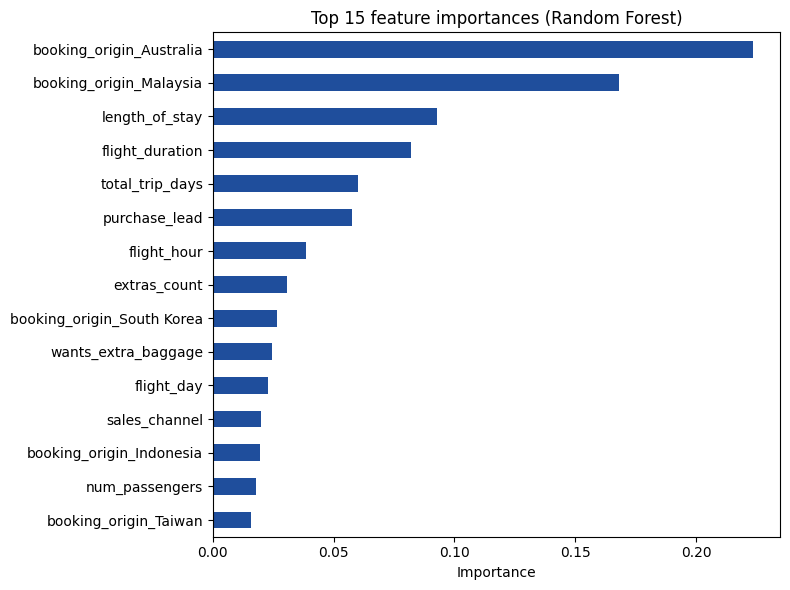

In [30]:
import pandas as pd

importances = pd.Series(best_model.feature_importances_, index=x_train.columns).sort_values()

plt.figure(figsize=(8, 6))
importances.tail(15).plot(kind='barh', color='#1f4e9c')
plt.title('Top 15 feature importances (Random Forest)')
plt.xlabel('Importance')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150)
plt.show()

In [31]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(best_model, x_test, y_test, scoring='roc_auc',
                              n_repeats=5, random_state=42, n_jobs=-1)
perm_importance = pd.Series(perm.importances_mean, index=x_test.columns).sort_values(ascending=False)
perm_importance.head(10).round(4)

booking_origin_Australia      0.0974
booking_origin_Malaysia       0.0233
flight_duration               0.0145
length_of_stay                0.0142
booking_origin_South Korea    0.0107
booking_origin_Taiwan         0.0075
sales_channel                 0.0073
wants_extra_baggage           0.0057
extras_count                  0.0046
booking_origin_Japan          0.0034
dtype: float64

## Findings
- Cross-validated ROC AUC: 0.7602; test ROC AUC: 0.7582. The model has moderate predictive power: useful for ranking customers by booking likelihood, not for confident individual predictions.
- Recall on bookers: 0.70, precision: 0.29 (F1-score: 0.41). Accuracy alone is misleading because ~85% of customers do not book.
- Most important features (Permutation Importance): booking_origin_Australia, booking_origin_Malaysia, flight_duration, and length_of_stay.
- Limitations: class imbalance, no customer-level behavioural data, and only one model family (Random Forest) was tuned.
- Next steps: try gradient boosting (XGBoost/LightGBM), threshold tuning and SHAP values.
